### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv("../data/raw/amz_uk_price_prediction_dataset.csv")
df.head(10)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
5,6,B09B97WSLF,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
6,7,B09B9615X2,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
7,8,B01MTB55WH,Anker Soundcore 2 Portable Bluetooth Speaker w...,4.7,103673,39.99,False,0,Hi-Fi Speakers
8,9,B016MO90GW,"Bluetooth Speaker, Anker Soundcore Speaker Upg...",4.7,29909,29.99,False,0,Hi-Fi Speakers
9,10,B09ZQF5GZW,RIENOK Bluetooth Speaker Portable Wireless Blu...,4.5,16014,29.99,False,0,Hi-Fi Speakers


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
frequency_table = df['category'].value_counts()
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [12]:
top_categories = df['category'].value_counts().head(10).index
display(top_categories)
df_top_categories = df[df['category'].isin(top_categories)]
df_top_categories.head(10)

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts', 'Manicure & Pedicure Products',
       'Skin Care', 'Make-up', 'Hair Care', 'Fragrances'],
      dtype='object', name='category')

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82165,89485,B08G2HBBB6,GoPro HERO9 - Waterproof Sports Camera with Fr...,4.5,5161,199.00,True,0,Sports & Outdoors
82166,89486,B09D15SFMQ,GoPro HERO10 Black - Waterproof Action Camera ...,4.4,2467,249.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
82170,89490,B0CF3VVTLG,GoPro HERO12 Black - Waterproof Action Camera ...,4.1,41,399.00,False,0,Sports & Outdoors
82171,89491,B01171X0UW,NEEWER 50 in 1 Action Camera Accessory Kit Com...,4.5,54495,32.49,False,0,Sports & Outdoors
82172,89492,B0BNK4Y288,GoPro Dual Battery Charger + 2 Enduro Batterie...,4.7,568,59.99,False,0,Sports & Outdoors


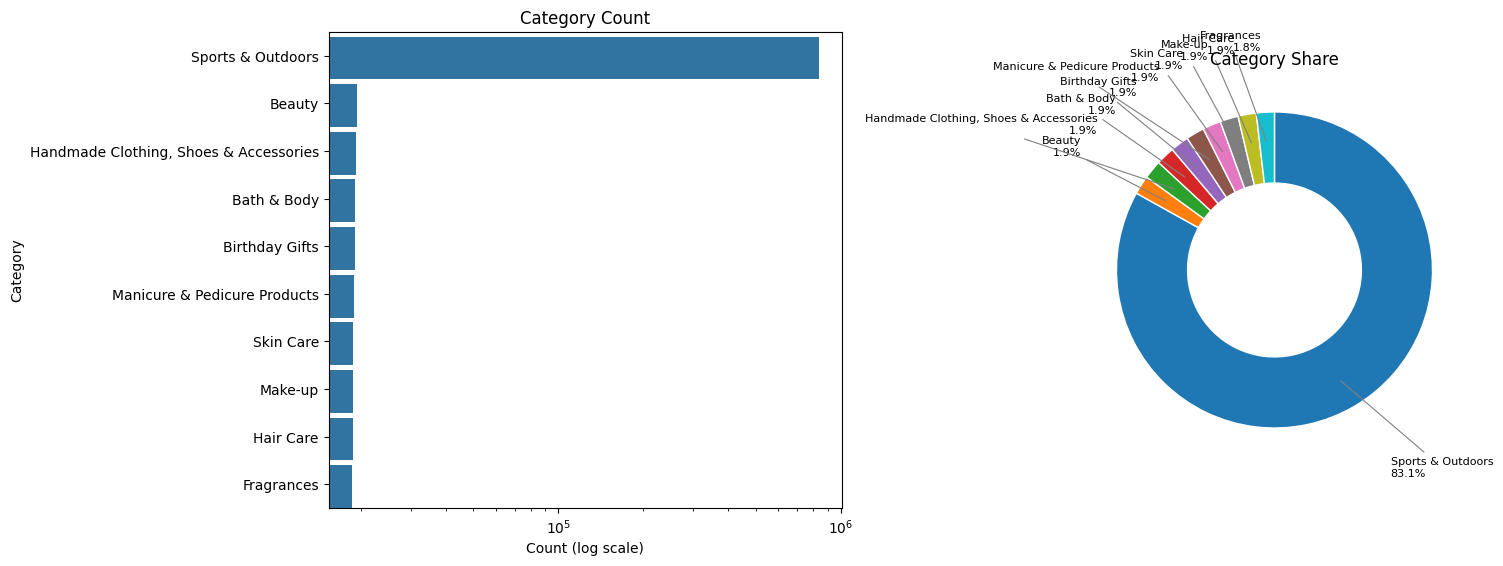

In [36]:
counts = df_top_categories['category'].value_counts()

fig, ax = plt.subplots(
    1, 2,
    figsize=(15, 6),
    gridspec_kw={'width_ratios': [1.3, 1]}
)

# left barplot
sns.barplot(
    y=counts.index,
    x=counts.values,
    ax=ax[0]
)

for bar in ax[0].patches:
    bar.set_height(0.9)

ax[0].set_xscale('log')

ax[0].set_title('Category Count')
ax[0].set_xlabel('Count (log scale)')
ax[0].set_ylabel('Category')

# right pie chart
wedges, _ = ax[1].pie(
    counts.values,
    startangle=90,
    counterclock=False,
    labels=None,
    wedgeprops={
        'width': 0.45,      
        'edgecolor': 'white'
    }
)

total = counts.sum()

for i, w in enumerate(wedges):

    angle = (w.theta1 + w.theta2) / 2

    x = np.cos(np.deg2rad(angle))
    y = np.sin(np.deg2rad(angle))

    pct = counts.iloc[i] / total * 100

    label = (
        f"{counts.index[i]}\n"
        f"{pct:.1f}%"
    )

    ax[1].annotate(
        label,
        xy=(x * 0.8, y * 0.8),
        xytext=(x * 1.45, y * 1.45),
        ha='left' if x > 0 else 'right',
        va='center',
        fontsize=8,
        arrowprops=dict(
            arrowstyle='-',
            color='gray',
            lw=0.8
        )
    )

ax[1].set_title('Category Share')

plt.tight_layout()
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [37]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [38]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

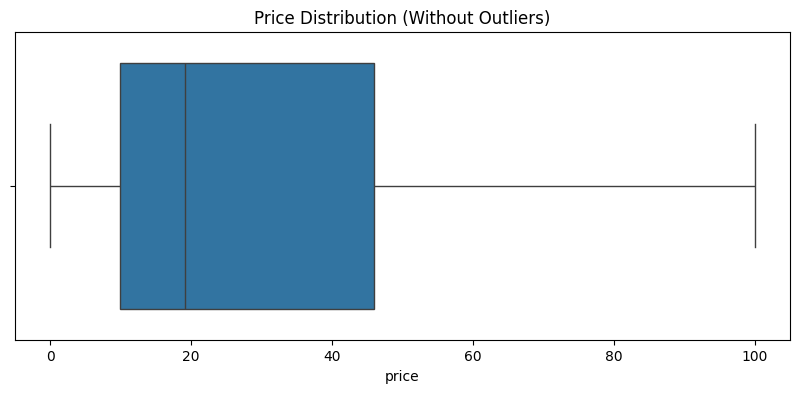

In [41]:
fig, ax = plt.subplots(figsize=(10,4))

sns.boxplot(
    x=df['price'],
    showfliers=False,
    ax=ax
)

ax.set_title('Price Distribution (Without Outliers)')

plt.show()

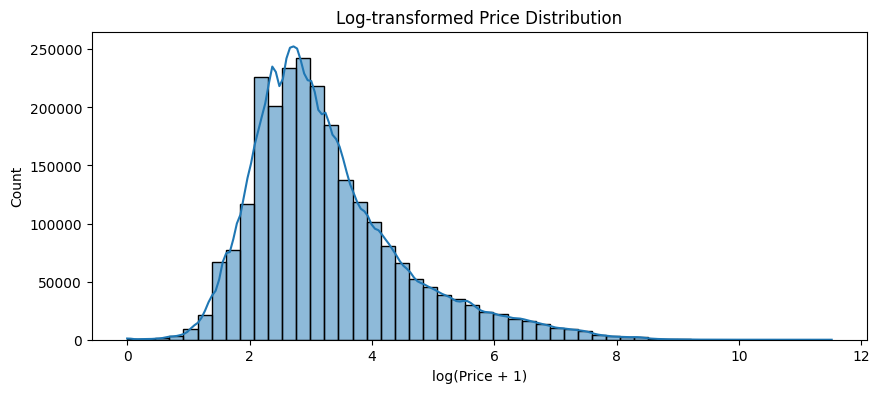

In [42]:
fig, ax = plt.subplots(figsize=(10,4))

sns.histplot(
    np.log1p(df['price']),
    bins=50,
    kde=True,
    ax=ax
)

ax.set_title('Log-transformed Price Distribution')
ax.set_xlabel('log(Price + 1)')

plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


In [44]:
rating = df['stars']

mean_rating = rating.mean()
median_rating = rating.median()
mode_rating = rating.mode()[0]

print(f"Mean: {mean_rating:.2f}")
print(f"Median: {median_rating:.2f}")
print(f"Mode: {mode_rating:.2f}")

Mean: 2.15
Median: 0.00
Mode: 0.00


In [45]:
print(rating.var())
print(rating.std())
Q1 = rating.quantile(0.25)
Q3 = rating.quantile(0.75)

IQR = Q3 - Q1

print(IQR)

4.817434029796862
2.1948653785134207
4.4


In [46]:
rating.skew()

np.float64(0.08120735761080985)

In [47]:
rating.kurtosis()

np.float64(-1.9260061280432985)

In [52]:
rating = df['stars']

Q1 = rating.quantile(0.25)
Q3 = rating.quantile(0.75)

summary = {
    "Mean": rating.mean(),
    "Median": rating.median(),
    "Mode": rating.mode()[0],
    "Variance": rating.var(),
    "Std Dev": rating.std(),
    "IQR": Q3 - Q1,
    "Skewness": rating.skew(),
    "Kurtosis": rating.kurtosis()
}

for k, v in summary.items():
    print(f"{k}: {v:.3f}")

Mean: 2.153
Median: 0.000
Mode: 0.000
Variance: 4.817
Std Dev: 2.195
IQR: 4.400
Skewness: 0.081
Kurtosis: -1.926


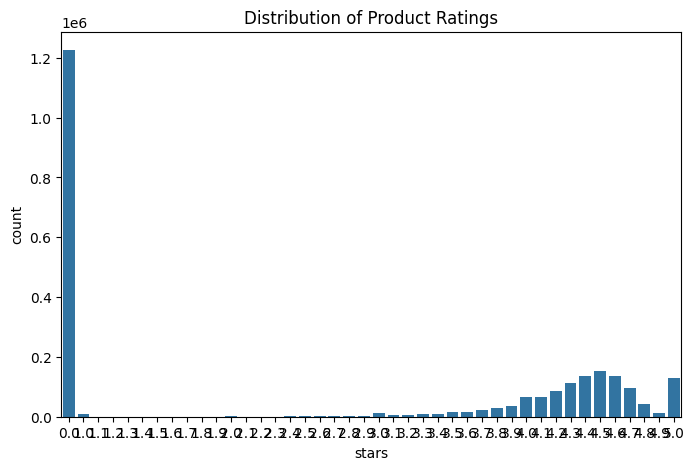

In [51]:
fig, ax = plt.subplots(figsize=(8,5))

sns.countplot(
    x='stars',
    data=df,
    ax=ax
)

ax.set_title('Distribution of Product Ratings')

plt.show()